# ESPRESSO: the M dwarf GJ 436

This notebook shows how to correct a star whose spectrum gtellcorr cannot synthesise
well, with a stellar template of your own. We use an ESPRESSO spectrum of GJ 436
(VLT, 2019 February 28), an M dwarf. Its spectrum is full of molecular bands, which a
template synthesised from atomic lines does not contain, so we model the star with a
spectrum from the PHOENIX library instead.

We proceed in four steps:

1. **The exposure.** We read the spectrum and look at two of its orders.
2. **The atmospheric profile.** It comes from ERA5, as before.
3. **The fit.** We turn the PHOENIX spectrum into a template file, tell gtellcorr how
   to read it, and run the fit.
4. **The result.** We look at the fitted columns and at two corrected orders.

**What you need.** gtellcorr with its LBLRTM bundle and reference files, and the data
below in one folder, pointed to by the environment variable `GTELLCORR_PAPER_DATA`:

- `gj436_espresso/ES_S2DA_2361220_2019-02-28T06:30:27.946_HR_2x1_U3.fits`: the
  ESPRESSO S2D spectrum (fibre A), from the ESO archive (data set
  `ADP.2021-04-15T10:08:22.397`, programme 1102.C-0744);
- `phoenix/lte03600-5.00-0.0.PHOENIX-ACES-AGSS-COND-2011-HiRes.fits` and
  `phoenix/WAVE_PHOENIX-ACES-AGSS-COND-2011.fits`, from the PHOENIX library
  (Husser et al. 2013, `phoenix.astro.physik.uni-goettingen.de`).

The atmospheric profile comes from ERA5, which needs a Copernicus account
(`WEATHER_KEYS`). No pySME or line list is needed, since the template comes from a
file.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from astropy.io import fits

import gtellcorr as gtc
from gtellcorr.data.atmosphere import full_profile_for_exposure
from gtellcorr.plotting import plot_order_fit, plot_profiles

data = Path(os.environ.get("GTELLCORR_PAPER_DATA", "paper_data"))
output = Path(os.environ.get("GTELLCORR_PAPER_OUT", "paper_runs")) / "espresso_gj436"
settings = gtc.Settings.load()
plt.rcParams["figure.dpi"] = 72  # keeps the figures in the notebook small
print("gtellcorr", gtc.__version__)

gtellcorr 0.10.0


## 1. The exposure

We read the spectrum with the ESPRESSO instrument description
(`instrument="VLT/ESPRESSO"`). Besides the epoch and the airmass, the ESPRESSO header
records the site and the weather measured at the telescope:

In [2]:
star = gtc.Star(name="GJ 436", teff=3586.0, logg=4.841, feh=0.1, vsini_kms=0.29, vsys_kms=9.8025)
obs = gtc.Observation.from_directory(
    data / "gj436_espresso", instrument="VLT/ESPRESSO", target=star
)
exposure = obs.exposures[0]
instrument = obs.instrument
print(
    f"{exposure.name}\nmid-exposure {exposure.time_utc:%Y-%m-%d %H:%M:%S} UTC, "
    f"airmass {exposure.airmass:.2f}, R = {exposure.resolution:.0f}"
)
print("site:", exposure.site.coords, "| on-site weather:", exposure.weather)

ES_S2DA_2361220_2019-02-28T06:30:27.946_HR_2x1_U3.fits
mid-exposure 2019-02-28 06:32:57 UTC, airmass 1.62, R = 140000
site: (-24.6268, -70.4045, 2648.0) | on-site weather: OnSiteWeather(T_K=286.53, RH_pct=38.0, P_hpa=744.25, dewpoint_K=None, time=None)


ESPRESSO records every echelle order twice, in two slices of the pupil, so a spectrum
has 170 rows, which gtellcorr calls orders; the two slices of an order cover the same
wavelengths. As for NEID, the molecular columns are fitted jointly on the anchor
orders of the instrument description: the slices of the orders with water lines
between 683 and 743 nm, and of the three O{sub}`2` bands (γ near 630 nm, B near 688 nm,
A near 762 nm). Let's list them, and look at two orders: order 138, around H-alpha,
which is not a fit order, and order 159, a water anchor order near 740 nm.

24 fit orders of 170: [128, 129, 130, 131, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 162, 163, 164, 165, 166, 167]


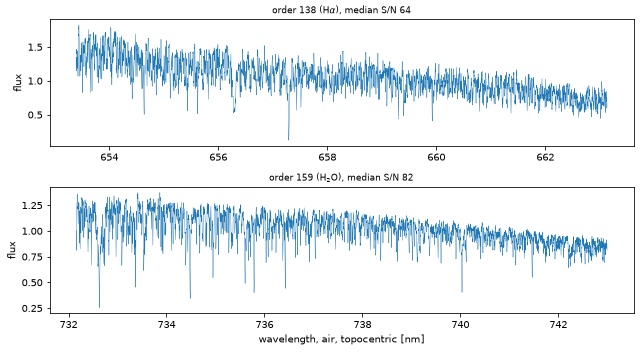

In [3]:
anchors = instrument.anchor_orders
fit_orders = sorted(set(anchors["h2o"]) | set(anchors["o2"]))
print(f"{len(fit_orders)} fit orders of {len(instrument.orders)}: {fit_orders}")

shown = {138: r"H$\alpha$", 159: r"H$_2$O"}
fig, axes = plt.subplots(2, 1, figsize=(9, 5))
for ax, (number, label) in zip(axes, shown.items(), strict=True):
    order = obs.read_order(exposure, number)
    snr = np.median(order.flux / order.err)
    ax.plot(order.wave_fit, order.flux, lw=0.4)
    ax.set_title(f"order {number} ({label}), median S/N {snr:.0f}", fontsize=9)
    ax.set_ylabel("flux")
axes[1].set_xlabel("wavelength, air, topocentric [nm]")
fig.tight_layout()

Unlike the A star of the previous notebook, GJ 436 absorbs almost everywhere: its
atomic and molecular lines are so dense that the true continuum is rarely reached, and
the telluric lines sit among them. Separating the two is only as good as the stellar
model, which is why the choice of template matters most for this star.

## 2. The atmospheric profile

The profile above Paranal at the middle of the exposure, built as in the first notebook
(ERA5 below, NRLMSIS-00 above); `plot_profiles` marks the on-site measurements of the
header:

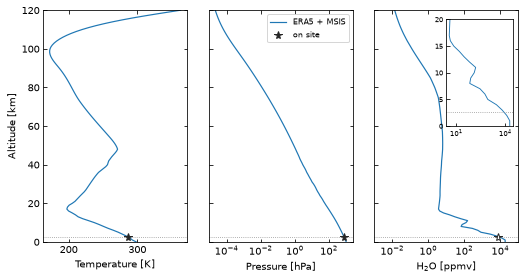

In [4]:
profile = full_profile_for_exposure(exposure, instrument, settings=settings)
fig, axes = plot_profiles(
    {"ERA5 + MSIS": profile},
    site_alt_km=exposure.site.alt_m / 1000,
    onsite=exposure.weather,
)

## 3. The fit

### The stellar template

gtellcorr reads a template from a text file with two columns, the wavelength in nm and
the flux normalised to the continuum. The PHOENIX spectrum differs from this in three
ways: its wavelengths are in Å and in vacuum, its flux is absolute, and its resolving
power is far above that of ESPRESSO. We take care of the first two ourselves, and leave
the rest to gtellcorr:

- we convert the wavelengths to nm and keep 600-800 nm, which holds every fit order;
- we divide the flux by a smooth upper envelope, so that it is roughly normalised. The
  envelope does not have to be exact: the continuum fitted in every order absorbs what
  remains;
- the conversion to air, the shift to the RV of the exposure and the broadening to the
  resolving power of ESPRESSO are done by gtellcorr when it reads the file.

Outside 600-800 nm the stellar model is 1. This does not matter here: the template is
used for the RV and for the fit, and every fit order lies inside it.

In [5]:
def upper_envelope(wave, flux, degree=5):
    # the 98th percentile per nm, fitted by a clipped polynomial
    edges = np.arange(wave[0], wave[-1] + 1.0, 1.0)
    bins = np.digitize(wave, edges)
    cw = np.array([wave[bins == i].mean() for i in np.unique(bins)])
    cf = np.array([np.percentile(flux[bins == i], 98) for i in np.unique(bins)])
    x = (cw - cw.mean()) / np.ptp(cw)
    keep = np.ones_like(cf, bool)
    for _ in range(10):
        coef = np.polyfit(x[keep], cf[keep], degree)
        r = cf - np.polyval(coef, x)
        new = r > -2.0 * np.std(r[keep])
        if np.array_equal(new, keep):
            break
        keep = new
    return np.polyval(coef, (wave - cw.mean()) / np.ptp(cw))


phoenix = data / "phoenix"
wave = fits.getdata(phoenix / "WAVE_PHOENIX-ACES-AGSS-COND-2011.fits") / 10.0  # nm, vacuum
spectrum = phoenix / "lte03600-5.00-0.0.PHOENIX-ACES-AGSS-COND-2011-HiRes.fits"
flux = np.asarray(fits.getdata(spectrum), float)
cut = (wave >= 600.0) & (wave <= 800.0)
wave, flux = wave[cut], flux[cut]
template = output / "GJ436_PHOENIX_lte03600-5.00-0.0_vacuum_rest_600-800nm.txt"
template.parent.mkdir(parents=True, exist_ok=True)
np.savetxt(
    template,
    np.column_stack([wave, flux / upper_envelope(wave, flux)]),
    fmt="%.6f %.8f",
    header="PHOENIX 3600/5.00: vacuum wavelength [nm], rest frame",
)
print(f"{wave.size} points, {wave[0]:.1f}-{wave[-1]:.1f} nm")

200001 points, 600.0-800.0 nm


### The settings

These are the settings of this fit, written out in full:

- `stellar = "template"` and `stellar_model.template_file`: the star is modelled with
  the PHOENIX file;
- `stellar_model.template_medium = "vacuum"`: the file has vacuum wavelengths, which
  gtellcorr converts to air, the medium of the ESPRESSO spectra;
- `stellar_model.template_frame = "rest"`: the file is in the rest frame of the star,
  so it is shifted to the RV of the exposure, measured by cross-correlation with the
  same template;
- `stellar_model.template_resolution = inf`: the model spectrum is treated as
  unbroadened by an instrument, and gtellcorr broadens it with a Gaussian to the
  start $R$ of the fit, here the fixed 140 000 below;
- `lsf.fit_resolution = false`, `lsf.resolution = 140000`: the resolving power is fixed
  at the nominal value of ESPRESSO. With the remaining mismatch between PHOENIX and the
  star, a fitted $R$ runs to its lower bound in the water orders;
- `continuum.order = 2`: a continuum of degree 2 per order instead of 5, since an
  ESPRESSO order covers only about 10 nm;
- `relcol_mode = "joint_orders"`: one H{sub}`2`O and one O{sub}`2` column shared by the
  24 fit orders, as for NEID;
- `wavelength.fit = false`: no wavelength correction (the default).

In [6]:
config = gtc.FitConfig.from_dict(
    {
        "stellar": "template",
        "stellar_model": {
            "template_file": str(template),
            "template_medium": "vacuum",
            "template_frame": "rest",
            "template_resolution": float("inf"),
        },
        "lsf": {"fit_resolution": False, "resolution": 140000.0},
        "continuum": {"order": 2},
        "relcol_mode": "joint_orders",
        "wavelength": {"fit": False},
    }
)
result = gtc.run(obs, config, output_dir=output, settings=settings, plot=False)

## 4. The result

### Fitted parameters

The columns shared by the 24 fit orders, and the fit statistics of each order:

In [7]:
table = result.exposures[0].order_table
fitted = table[table["used_in_fit"]]
relcol, relcol_err = {}, {}
for _, row in fitted.iterrows():  # each order lists the molecules fitted in it
    relcol |= json.loads(row["relcol"])
    relcol_err |= json.loads(row["relcol_err"])
for name in relcol:
    print(f"s_{name.upper()}: {relcol[name]:.4f} +- {relcol_err[name]:.4f}")
print(f"joint reduced chi2: {fitted['chi2_reduced_joint'].iloc[0]:.1f}")
fitted[["order", "wave_lo", "wave_hi", "molecules", "chi2_reduced_order", "masked_frac"]].round(3)

s_O2: 1.0587 +- 0.0052
s_H2O: 1.5856 +- 0.0097
joint reduced chi2: 179.3


,order,wave_lo,wave_hi,molecules,chi2_reduced_order,masked_frac
128,128,620.045,629.308,"[""o2""]",115.682,0.000
129,129,620.045,629.308,"[""o2""]",106.703,0.000
130,130,626.439,635.794,"[""o2""]",118.520,0.000
131,131,626.439,635.795,"[""o2""]",110.043,0.000
146,146,682.771,692.926,"[""h2o"", ""o2""]",403.399,0.010
147,147,682.771,692.927,"[""h2o"", ""o2""]",370.017,0.010
148,148,690.533,700.797,"[""h2o"", ""o2""]",420.884,0.000
149,149,690.533,700.798,"[""h2o"", ""o2""]",385.766,0.000
150,150,698.474,708.849,"[""h2o""]",241.557,0.000
151,151,698.474,708.850,"[""h2o""]",223.846,0.000


The spectrum holds 1.59 times the water of the ERA5 profile, and 5.9 % more O{sub}`2`
than the profile. The reduced $\chi^2$ is 179 for the joint fit and 26-421 in the single
orders, far above 1: the template does not reproduce the M dwarf line by line, and
these residuals, not the noise, dominate $\chi^2$. It is lowest in the orders of the
O{sub}`2` A band (162-165), where the telluric lines are strongest compared with the
stellar ones.

In such a fit the formal uncertainties (0.5-1 %) underestimate the real errors, and the
O{sub}`2` column in particular should not be taken at face value. It is 5.9 % above 1,
against 2 % for the K dwarf HAT-P-26 observed with the same instrument (next notebook).
In an injection-recovery simulation of PEPSI spectra, a synthetic M-dwarf template that
differed from the true stellar spectrum raised O{sub}`2` by 40 % or more, so a mismatch
of a few percent here is no surprise.

### The corrected orders

The fits of the two orders of Section 1. Order 138 was not fitted: it is corrected with
the shared columns. The flux of this red star is normalised by its median, so its
continuum sits well above 1:

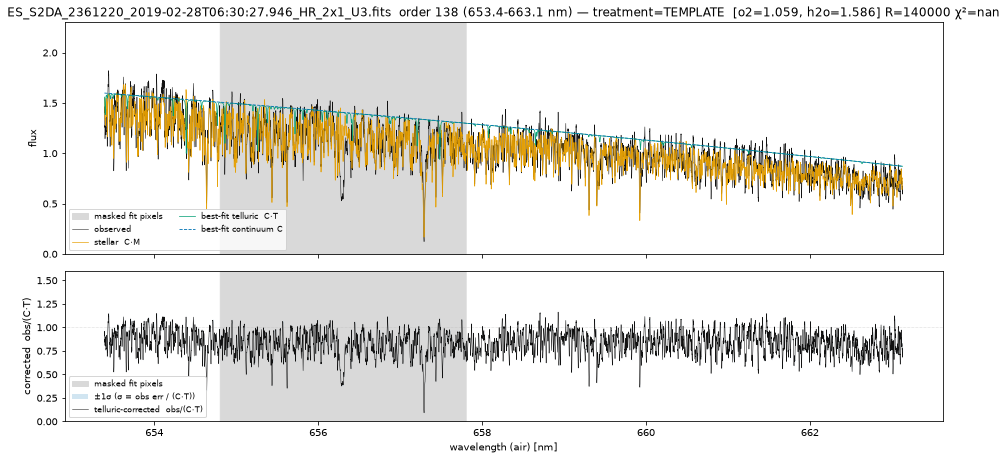

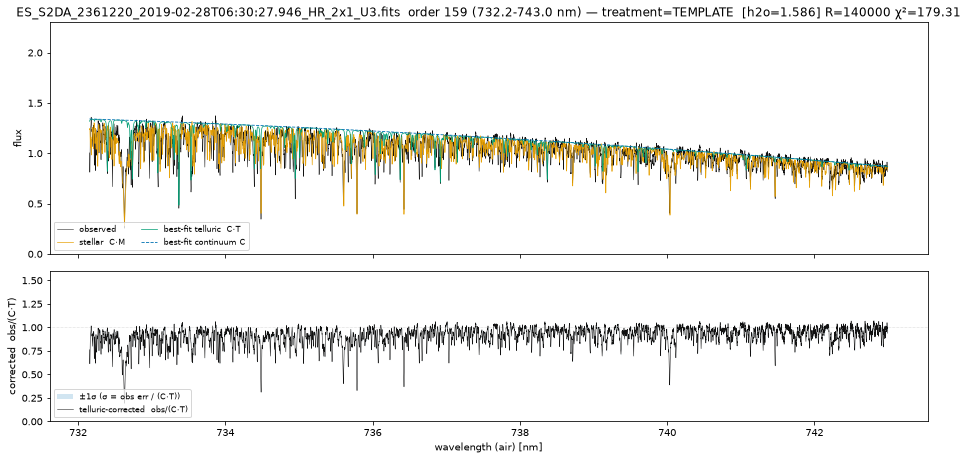

In [8]:
path = result.exposures[0].path
for number in shown:
    fig, axes = plot_order_fit(str(path), order=number, out=False, flux_ylim=(0.0, 2.3))

Order 138 shows the difficulty of this star. The observed spectrum (black) is a dense
forest of stellar lines; the PHOENIX template (orange) follows their overall pattern
but not every line. The telluric lines in this order are few weak water lines, and
they are removed; the corrected spectrum keeps the stellar lines, H-alpha included
(the grey band is the activity window left out of the fit). In order 159 the water
lines are deeper. The moderate ones are removed, and what the corrected spectrum
shows are the stellar lines, with residuals at the cores of the deepest telluric
lines.